In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import warnings
warnings.filterwarnings('ignore')

# 1. Load the Dataset
# Replace 'zomato.csv' with your actual uploaded file name
df = pd.read_csv('zomato.csv')

# 2. Data Cleaning
# Drop duplicates
df.drop_duplicates(inplace=True)

# Clean the 'rate' column (usually formatted as '4.1/5', 'NEW', or '-')
def clean_rate(x):
    if isinstance(x, str):
        x = x.split('/')[0].strip()
        if x == 'NEW' or x == '-':
            return np.nan
        try:
            return float(x)
        except ValueError:
            return np.nan
    return x

if 'rate' in df.columns:
    df['rate'] = df['rate'].apply(clean_rate)

# Clean the cost column (usually contains commas like '1,200')
cost_col = 'approx_cost(for two people)'
if cost_col in df.columns:
    df[cost_col] = df[cost_col].astype(str).apply(lambda x: x.replace(',', ''))
    df[cost_col] = pd.to_numeric(df[cost_col], errors='coerce')

# Drop rows with null values in critical columns to ensure accurate visualizations
df.dropna(subset=['rate', cost_col, 'location', 'cuisines'], inplace=True)

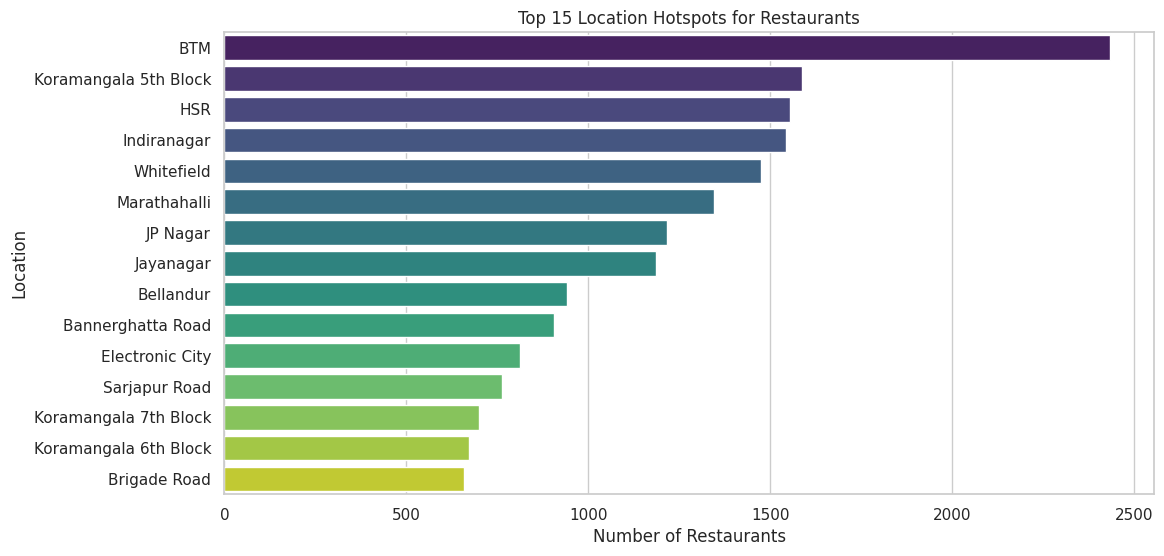

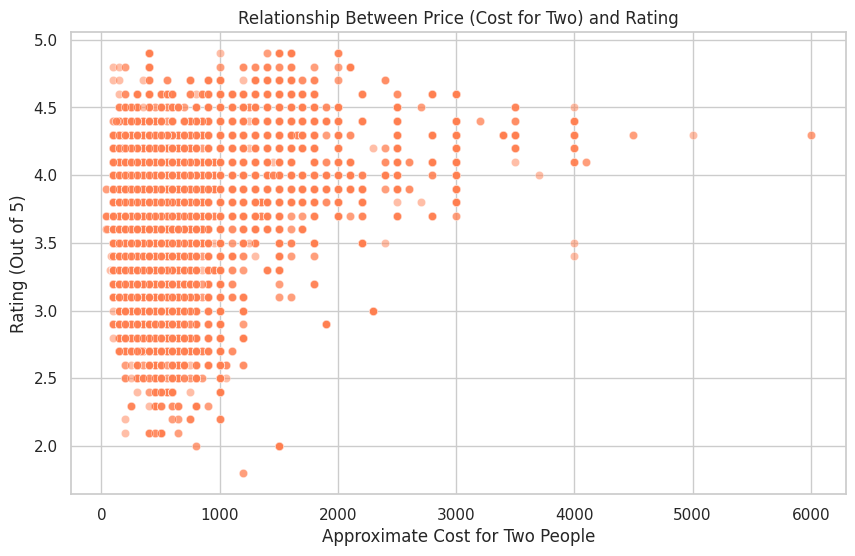

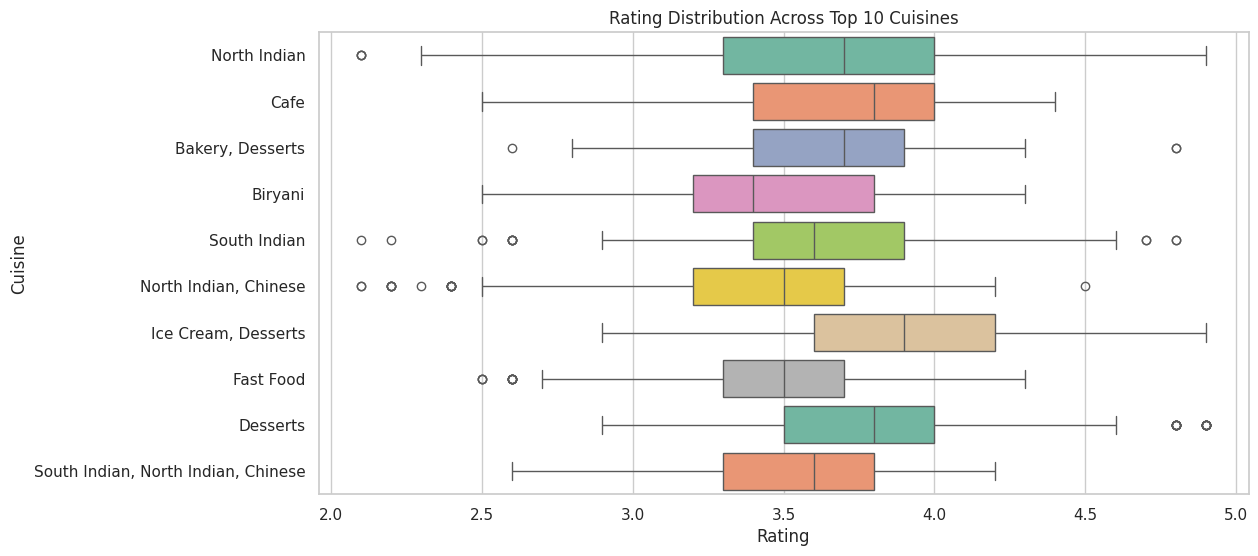

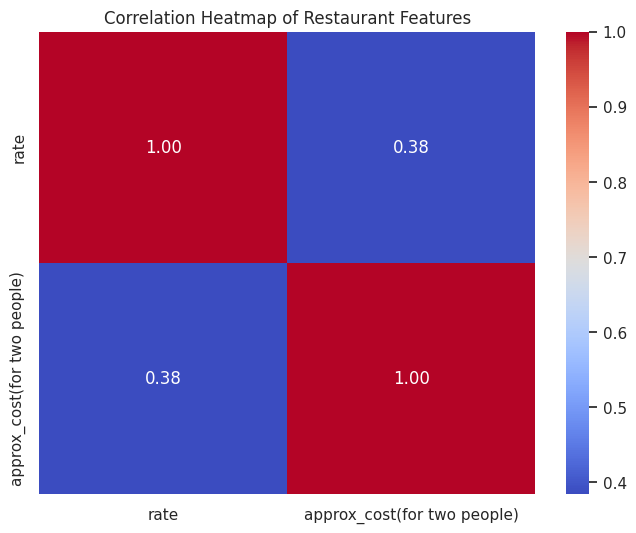

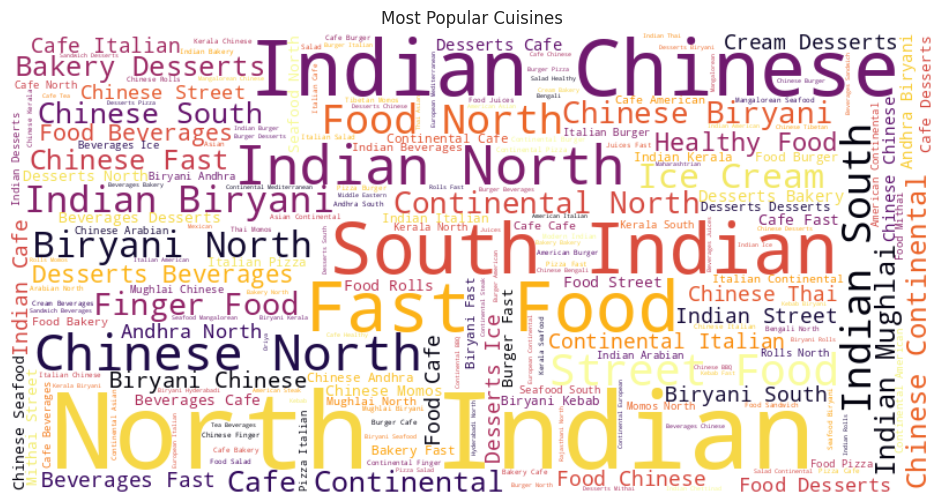

In [2]:
# 3. Explore Relationships & Build Visualizations[cite: 1]
sns.set_theme(style="whitegrid")

# Visualization A: Location Hotspots (Top 15 Locations)
plt.figure(figsize=(12, 6))
sns.countplot(y=df['location'], order=df['location'].value_counts().iloc[:15].index, palette='viridis')
plt.title('Top 15 Location Hotspots for Restaurants')
plt.xlabel('Number of Restaurants')
plt.ylabel('Location')
plt.show()

# Visualization B: Price vs Rating Relationship
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df[cost_col], y=df['rate'], alpha=0.5, color='coral')
plt.title('Relationship Between Price (Cost for Two) and Rating')
plt.xlabel('Approximate Cost for Two People')
plt.ylabel('Rating (Out of 5)')
plt.show()

# Visualization C: Cuisine vs Rating (Top 10 Most Common Cuisines)
top_cuisines = df['cuisines'].value_counts().head(10).index
plt.figure(figsize=(12, 6))
sns.boxplot(x='rate', y='cuisines', data=df[df['cuisines'].isin(top_cuisines)], palette='Set2')
plt.title('Rating Distribution Across Top 10 Cuisines')
plt.xlabel('Rating')
plt.ylabel('Cuisine')
plt.show()

# Visualization D: Heatmap of Numerical Features
plt.figure(figsize=(8, 6))
num_cols = df.select_dtypes(include=[np.number])
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Restaurant Features')
plt.show()

# Visualization E: Wordcloud for Popular Cuisines
cuisine_text = ' '.join(df['cuisines'].dropna().astype(str))
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='inferno').generate(cuisine_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Popular Cuisines')
plt.show()

In [3]:
# 1. Location Hotspots (Top 10 areas with the most restaurants)
print("--- Top 10 Location Hotspots ---")
location_counts = df['location'].value_counts().head(10)
print(location_counts)
print("\n")

# 2. Cuisine vs Rating (Average rating for the most popular cuisines)
# We filter for cuisines that have at least 50 restaurants to get reliable averages
print("--- Average Rating by Popular Cuisines ---")
popular_cuisines = df['cuisines'].value_counts()[df['cuisines'].value_counts() > 50].index
cuisine_ratings = df[df['cuisines'].isin(popular_cuisines)].groupby('cuisines')['rate'].mean()
top_rated_cuisines = cuisine_ratings.sort_values(ascending=False).head(10)
print(top_rated_cuisines)
print("\n")

# 3. Price vs Rating Correlation
print("--- Price vs Rating Correlation ---")
# Calculate the Pearson correlation coefficient between cost and rating
correlation = df[[cost_col, 'rate']].corr().iloc[0, 1]
print(f"Correlation coefficient: {correlation:.4f}")

# Grouping ratings into price buckets for clearer insight
df['Price_Bucket'] = pd.qcut(df[cost_col], q=4, labels=['Budget', 'Mid-Range', 'Expensive', 'Luxury'])
price_bucket_ratings = df.groupby('Price_Bucket')['rate'].mean()
print("\nAverage Rating by Price Bucket:")
print(price_bucket_ratings)

--- Top 10 Location Hotspots ---
location
BTM                      2434
Koramangala 5th Block    1587
HSR                      1553
Indiranagar              1544
Whitefield               1475
Marathahalli             1346
JP Nagar                 1216
Jayanagar                1185
Bellandur                 942
Bannerghatta Road         907
Name: count, dtype: int64


--- Average Rating by Popular Cuisines ---
cuisines
Pizza, Cafe, Italian                      4.411765
Cafe, Desserts                            4.111340
Desserts, Beverages                       4.088172
Cafe, Continental, Beverages              4.048438
North Indian, Mughlai                     3.923611
Desserts, Ice Cream                       3.922826
Cafe, Continental, Italian                3.920000
Cafe, Continental                         3.916239
Andhra, Biryani, North Indian, Chinese    3.909211
Ice Cream, Desserts                       3.881724
Name: rate, dtype: float64


--- Price vs Rating Correlation ---
Cor